<a href="https://colab.research.google.com/github/lamu107/Fatema-1015/blob/main/1015_Assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student ID : 15

Observed and expected frequencies:
C        Observed:  35   Expected: 32.75
C++      Observed:  30   Expected: 32.75
Java     Observed:  31   Expected: 32.75
Python   Observed:  35   Expected: 32.75

H0: Students have equal preference for all four languages.
H1: Students' preferences are not equal across all four languages.

Chi-square statistic: 0.6336
Degrees of freedom: 3
Critical value (alpha = 0.05): 7.8147
P-value: 0.8887

Decision: Fail to reject H0.
Conclusion: There is not sufficient evidence that preferences differ from equal preference for the four languages.


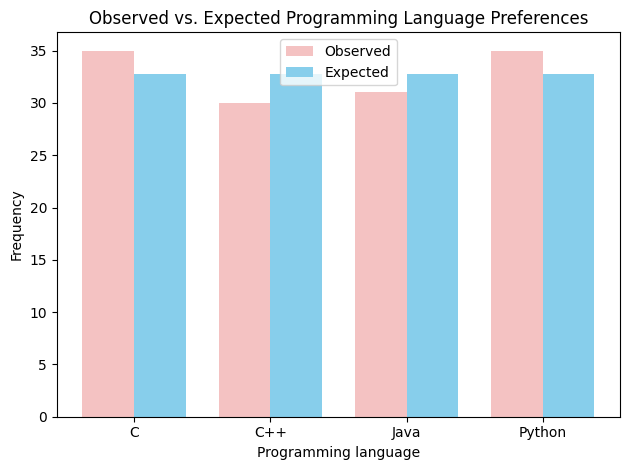

In [4]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
#last two id digit
d = 15

languages = ["C", "C++", "Java", "Python"]

# Observed frequencies from the assignment formulas
observed = np.array([
    20 + d,
    25 + (d % 10),
    30 + (d % 7),
    35 + (d % 5)
])

# Equal-preference hypothesis: same expected frequency for each language
total = observed.sum()
expected = np.full(len(observed), total / len(observed), dtype=float)

# Chi-square goodness-of-fit test
chi_square_stat = np.sum((observed - expected) ** 2 / expected)
df = len(observed) - 1
alpha = 0.05
p_value = stats.chi2.sf(chi_square_stat, df)
critical_value = stats.chi2.ppf(1 - alpha, df)

print(f"Student ID : {d:02d}")
print("\nObserved and expected frequencies:")
for language, obs, exp in zip(languages, observed, expected):
    print(f"{language:<8} Observed: {obs:>3}   Expected: {exp:.2f}")

print("\nH0: Students have equal preference for all four languages.")
print("H1: Students' preferences are not equal across all four languages.")
print(f"\nChi-square statistic: {chi_square_stat:.4f}")
print(f"Degrees of freedom: {df}")
print(f"Critical value (alpha = {alpha}): {critical_value:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < alpha:
    print("\nDecision: Reject H0.")
    print("Conclusion: There is sufficient evidence that language preferences differ.")
else:
    print("\nDecision: Fail to reject H0.")
    print(
        "Conclusion: There is not sufficient evidence that preferences differ "
        "from equal preference for the four languages."
    )

x = np.arange(len(languages))
width = 0.38

plt.bar(
    x - width / 2, observed, width,
    label="Observed",
    color="#F4C2C2"  # Baby pink
)
plt.bar(
    x + width / 2, expected, width,
    label="Expected",
    color="#87CEEB"  # Sky blue
)

plt.xticks(x, languages)
plt.xlabel("Programming language")
plt.ylabel("Frequency")
plt.title("Observed vs. Expected Programming Language Preferences")
plt.legend()
plt.tight_layout()
plt.show()